<a href="https://colab.research.google.com/github/HamidBekamiri/BDS-Teaching/blob/main/M2_05_countries_macro_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Part 5 · Zooming out: the network of countries

*M2 Network Analysis · Mapping collaboration with networks*

**The story so far.** Parts 2–4 analysed inventors. The same patent data also tells us which *countries* work together.

> **Today's question:** If we replace inventors by their countries, which countries collaborate, and who is the bridge between them?

**You will learn to**

1. Re-use the two-mode → projection recipe at a different level (countries).
2. Find the most international applications and the strongest country partnerships.
3. Identify **bridge** countries with betweenness, and test what happens when one is removed.
4. Build an **interactive** network plot with `pyvis`.

In [ ]:
# In Google Colab everything below is already installed.
# Locally: pip install networkx pandas matplotlib scipy
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 40)
TEAL, ORANGE, GREY = "#0097A7", "#FFA940", "#B0BEC5"

In [ ]:
def draw(G, pos, node_size=60, node_color=TEAL, labels=False, title=None, ax=None,
         cmap=None, edge_alpha=0.35, width=0.8, font_size=8):
    """One consistent way of drawing a network, used throughout the course."""
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    arrows = dict(arrows=True, arrowsize=7, node_size=node_size) if G.is_directed() else {}
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=edge_alpha, width=width, edge_color="#78909C", **arrows)
    nx.draw_networkx_nodes(G, pos, ax=ax, node_size=node_size, node_color=node_color,
                           cmap=cmap, edgecolors="white", linewidths=0.6)
    if labels:
        nx.draw_networkx_labels(G, pos, ax=ax, labels=labels if isinstance(labels, dict) else None,
                                font_size=font_size)
    if title:
        ax.set_title(title, loc="left", fontweight="bold")
    ax.axis("off")
    return ax


def community_colors(G, membership):
    """A distinct colour per community: membership = {node: community number}."""
    return [plt.cm.tab20(membership[n] % 20) for n in G]

In [ ]:
from networkx.algorithms import bipartite

URL = ("https://raw.githubusercontent.com/hamidb201214-svg/Lectures/"
       "refs/heads/main/data/epo_inventors_clean.csv")
df = pd.read_csv(URL, low_memory=False).dropna(subset=["ctry_code"])
df["ctry_code"].value_counts().head(10)

ctry_code
DK    5013
US     269
DE     209
FI     133
GB      82
IN      82
FR      66
CH      57
NL      55
SE      46
Name: count, dtype: int64

## 1. Country ↔ application (two-mode)

Same recipe as Part 2, but now the first mode is the **country** of each inventor:
an edge means *this country had at least one inventor on this application*.

In [ ]:
pairs = df[["ctry_code", "appln_id"]].drop_duplicates()

BC = nx.Graph()
BC.add_nodes_from(pairs["ctry_code"].unique(), bipartite="country")
BC.add_nodes_from(pairs["appln_id"].unique(),  bipartite="application")
BC.add_edges_from(pairs.itertuples(index=False, name=None))

countries = list(pairs["ctry_code"].unique())
apps      = list(pairs["appln_id"].unique())
print(BC, "|", len(countries), "countries,", len(apps), "applications")

Graph with 2142 nodes and 2789 edges | 41 countries, 2101 applications


### Two-mode facts
- degree of an **application** = how many countries were involved (how *international* it is)
- degree of a **country** = in how many applications its inventors took part

24.5% of applications involve more than one country
most international application: 548235870 with 5 countries: ['DK', 'MY', 'SG', 'UA', 'US']


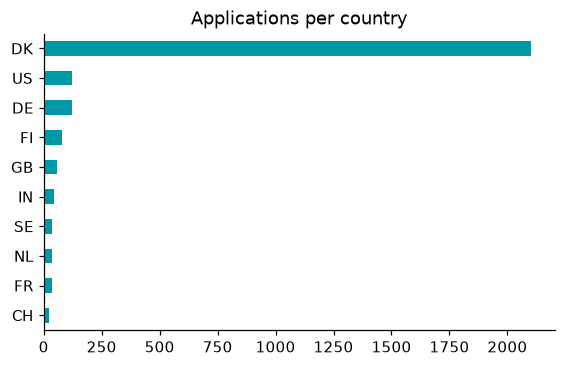

In [ ]:
n_countries = pd.Series({a: BC.degree(a) for a in apps})
print(f"{(n_countries > 1).mean():.1%} of applications involve more than one country")
print("most international application:", n_countries.idxmax(), "with", n_countries.max(), "countries:",
      sorted(BC.neighbors(n_countries.idxmax())))

portfolio = pd.Series({c: BC.degree(c) for c in countries}).sort_values(ascending=False)
portfolio.head(10).plot.barh(color=TEAL, figsize=(6, 3.5), title="Applications per country").invert_yaxis()
plt.show()

## 2. Project to a country–country network

Two countries are tied if they share an application; the **weight** = number of shared applications.

In [ ]:
def ordered(H):
    """Same node and edge order on every computer, so layouts and communities are reproducible."""
    R = nx.Graph()
    R.add_nodes_from(sorted(H.nodes(data=True)))
    R.add_edges_from(sorted((min(u, v), max(u, v), d) for u, v, d in H.edges(data=True)))
    return R

GC = ordered(bipartite.weighted_projected_graph(BC, countries))
GC.remove_nodes_from(list(nx.isolates(GC)))     # countries with no international co-invention
print(GC)

pd.DataFrame(sorted(GC.edges(data="weight"), key=lambda e: -e[2])[:10],
             columns=["country 1", "country 2", "shared applications"])

Graph with 41 nodes and 118 edges


,country 1,country 2,shared applications
0,DK,US,124
1,DE,DK,122
2,DK,FI,80
3,DK,GB,59
4,DK,IN,43
5,DK,SE,36
6,DK,FR,35
7,DK,NL,35
8,CH,DK,24
9,CN,DK,22


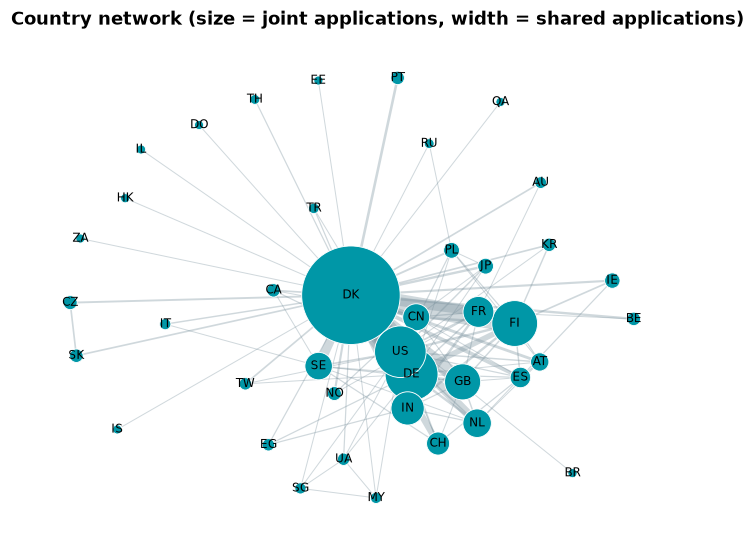

In [ ]:
pc = nx.spring_layout(GC, seed=4, weight=None)
w = dict(GC.degree(weight="weight"))
draw(GC, pc, node_size=[30 + 6 * w[c] for c in GC], labels=True, font_size=8,
     width=[0.5 + 0.15 * d for _, _, d in GC.edges(data="weight")],
     title="Country network (size = joint applications, width = shared applications)")
plt.show()

The picture is **star-like**: the data are Danish patents, so Denmark (DK) is tied to almost every country.
This is a **sampling effect**: always ask how the data were collected before interpreting centrality.

## 3. Bridges and degrees of separation

Portugal and Japan never share an application here. Are they connected at all?

In [ ]:
print("PT-JP tie?", GC.has_edge("PT", "JP"))
print("shortest path:", " -> ".join(nx.shortest_path(GC, "PT", "JP")))

PT-JP tie? False
shortest path: PT -> DK -> JP


In [ ]:
bc = pd.Series(nx.betweenness_centrality(GC), name="betweenness").sort_values(ascending=False)
bc.head(6).round(3)

DK    0.745
US    0.069
DE    0.030
FR    0.012
FI    0.012
CN    0.009
Name: betweenness, dtype: float64

### 🔎 What if the bridge disappears?
Remove Denmark and see how much of the network stays connected. This is a simple **robustness** test.

with DK   : 1 component of 41 countries
without DK: 12 components; largest has 28 countries: ['AT', 'AU', 'BE', 'CA', 'CH', 'CN', 'DE', 'EG', 'ES', 'FI', 'FR', 'GB', 'IE', 'IN', 'IT', 'JP', 'KR', 'MY', 'NL', 'NO', 'PL', 'RU', 'SE', 'SG', 'TR', 'TW', 'UA', 'US']


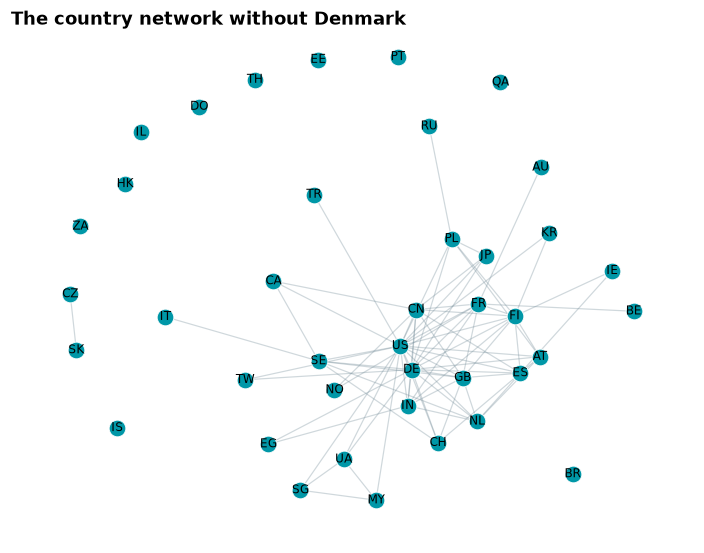

In [ ]:
no_dk = GC.copy()
no_dk.remove_node("DK")
comps = sorted(nx.connected_components(no_dk), key=len, reverse=True)
print(f"with DK   : 1 component of {GC.number_of_nodes()} countries")
print(f"without DK: {len(comps)} components; largest has {len(comps[0])} countries: {sorted(comps[0])}")

draw(no_dk, pc, node_size=120, labels=True, font_size=8, title="The country network without Denmark")
plt.show()

A surprise: most countries **stay connected** without Denmark. The foreign co-inventors on these patents
(US, DE, FI, GB, IN, ...) also share applications *with each other*, so they do not need DK as a go-between.
Only the countries tied to DK alone become isolated. Betweenness tells you who sits on the shortest paths;
the removal test tells you whether there is an **alternative route**.

## 4. An interactive view

Static plots are good for reports; interactive plots are good for exploring. `pyvis` writes an HTML page in which
you can drag nodes, zoom and hover.

In [ ]:
try:
    import pyvis
except ImportError:
    %pip install -q pyvis

In [ ]:
from pyvis.network import Network
from IPython.display import HTML, display

net = Network(height="550px", width="100%", notebook=True, cdn_resources="in_line")
for c in GC:
    net.add_node(c, label=c, size=8 + 2 * np.sqrt(w[c]),
                 title=f"{c}: {w[c]} joint applications, betweenness {bc[c]:.2f}")
for u, v, d in GC.edges(data="weight"):
    net.add_edge(u, v, value=d, title=f"{u}-{v}: {d} shared applications")

net.save_graph("country_network.html")        # open this file in a browser too
display(HTML(net.generate_html()))

## 🧑‍💻 Your turn

1. Which partnerships **not** involving DK are the strongest? (Filter the edge list.)
2. Do the same projection with **cities** (`city` column) instead of countries for Danish inventors only.
   Which Danish cities are bridges?
3. Make the interactive plot of the inventor **core** from Part 2, with node colour = Louvain community.

In [ ]:
# your code here

## ✅ Key takeaways
- The **two-mode → projection** recipe works at any level: inventors, cities, countries.
- Edge weights reveal the strongest partnerships; paths reveal indirect links (PT → DK → JP).
- **Betweenness** finds bridge countries; removing a bridge tests **robustness**.
- How the data were sampled (Danish patents) shapes who looks central.

**Next → Part 6:** what if ties have a **direction** (I ask *you* for advice) and come in several **types**?